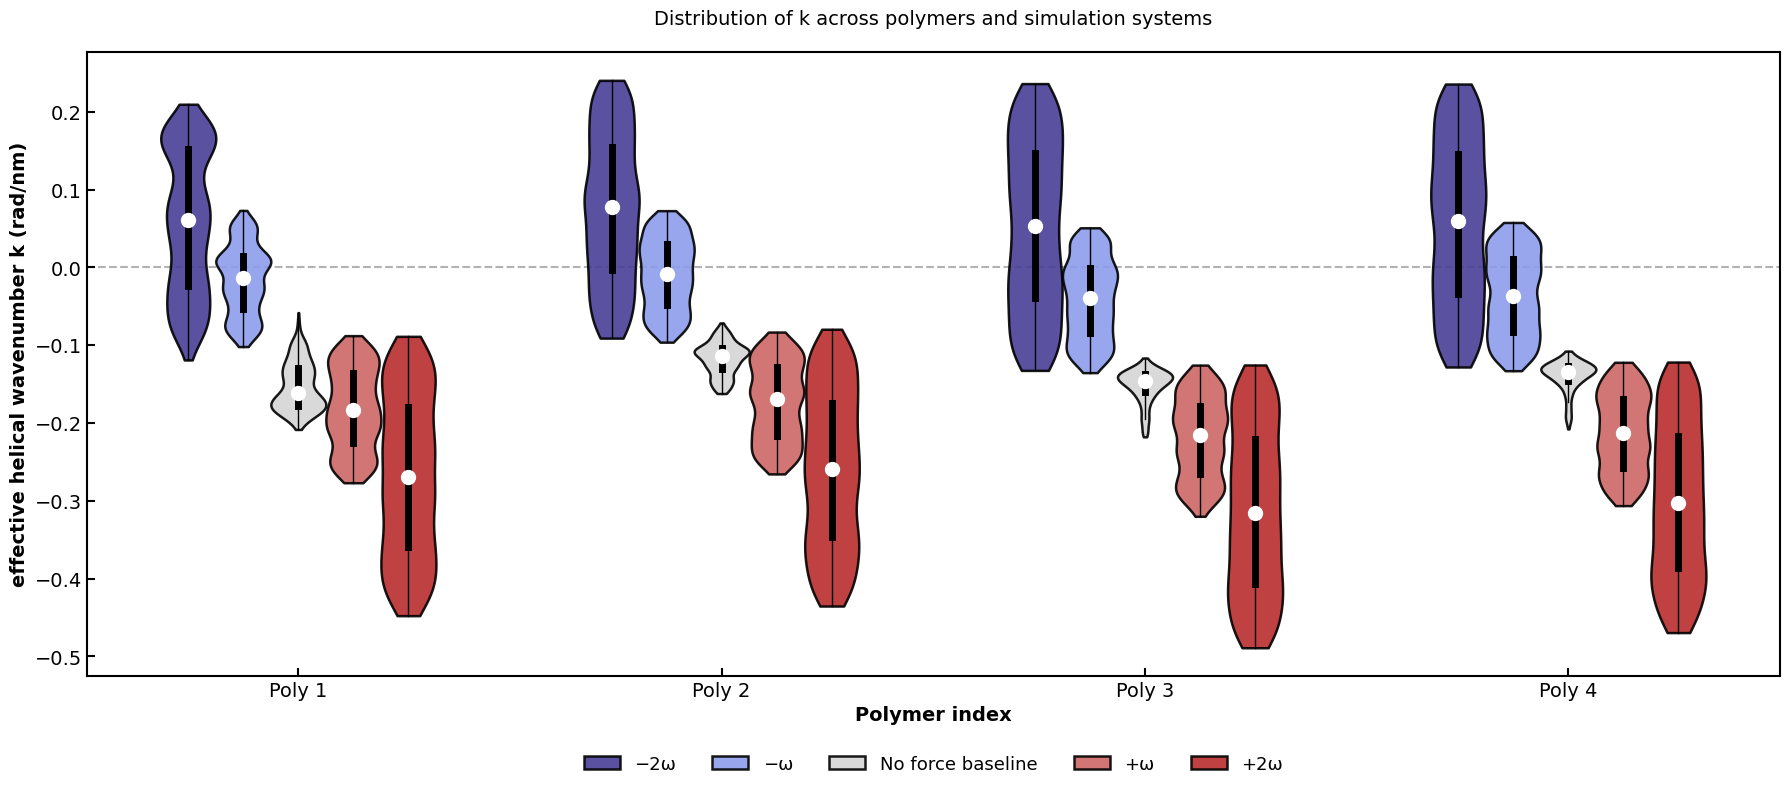

In [12]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

files = {
    "−2ω": "k_temporal_minus2x.csv", # frame save rate 0.05 ns
    "−ω": "k_temporal_minus.csv",    # frame save rate 0.05 ns
    "No force baseline": "k_temporal_prod.csv",      # frame save rate 0.1 ns 
    "+ω": "k_temporal_plus.csv",      # frame save rate 0.05 ns
    "+2ω": "k_temporal_plus2x.csv",   # frame save rate 0.05 ns
}

frames = []

for system, path in files.items():
    df = pd.read_csv(path)
    long_df = df.melt(id_vars="Time_ns",value_vars=[f"Poly_{i}" for i in range(1, 5)],
                    var_name="Polymer", value_name="k")    # makes a col called Polymer which contains Poly_1..Poly_4, another col called k: containing the vals in the columns 
    long_df["System"] = system  # adds another col containing the system name 
    frames.append(long_df)

# Combine all the systems into one df 
plot_df = pd.concat(frames, ignore_index=True)
plot_df = plot_df.dropna(subset=["k"])

# Rename polymer labels
plot_df["Polymer"] = plot_df["Polymer"].str.replace("_", " ", regex=False)

palette = {
    "−2ω": "#3D2FA5",
    "−ω": "#7C92FB",
    "No force baseline":"#D5D5D5",# "#e5e5ff",
    "+ω": "#dd5555",
    "+2ω": "#d01515",
    
}

fig, ax = plt.subplots(figsize=(18, 8))        #
sns.violinplot(
    data=plot_df,
    x="Polymer",
    y="k",
    hue="System",
    order=[f"Poly {i}" for i in range(1, 5)],
    hue_order=["−2ω", "−ω", "No force baseline", "+ω", "+2ω"],
    palette=palette,
    inner="box",      # has 2 dotted lines fr the 25q1, 50q2, 75q3 
    inner_kws={
        "box_width": 5,
        "whis_width": 1,
        "marker": "o",
        "markersize": 10,
        "markerfacecolor": "white",
        "markeredgecolor": "black"},
    alpha=0.9,
    cut=0,
    density_norm="width",
    linecolor="black",
    linewidth=1.8,
    width=0.65, 
    ax=ax
)
ax.axhline(y=0, color="gray",linestyle="--",linewidth=1.5, alpha=0.6,zorder=0)
ax.set_xlabel("Polymer index", fontsize=14, fontweight="bold")
ax.set_ylabel("effective helical wavenumber k (rad/nm)", fontsize=14, fontweight="bold")
ax.set_title("Distribution of k across polymers and simulation systems", fontsize=14, pad=20)
ax.tick_params(axis="both", labelsize=14, length=6, width=1.5,direction="in")
ax.legend(
    title=None,
    frameon=False,
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    fontsize=13
)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
    spine.set_color("black")

plt.tight_layout()
plt.savefig("k_violin_4polymers_5systems.png", dpi=300, bbox_inches="tight")
plt.show()
